<a href="https://colab.research.google.com/github/Abeer-24/NLP/blob/main/Automatic_Document_Classification_and_Separation_using_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

In [2]:
documents = [
    "The football team won the championship match.",
    "The cricket player scored a century.",
    "The basketball team played an excellent game.",
    "The tennis tournament starts next week.",
    "The government announced new education policies.",
    "The election campaign started in the country.",
    "The parliament discussed a new law.",
    "Political leaders attended the public meeting.",
    "Artificial intelligence is changing technology.",
    "Python is a popular programming language.",
    "Machine learning helps computers learn from data.",
    "New smartphones have advanced processors.",
    "The company reported increased annual profits.",
    "The stock market showed positive growth.",
    "Businesses are investing in new markets.",
    "The bank announced a new financial strategy."
]

labels = [
    "Sports", "Sports", "Sports", "Sports",
    "Politics", "Politics", "Politics", "Politics",
    "Technology", "Technology", "Technology", "Technology",
    "Business", "Business", "Business", "Business"
]

df = pd.DataFrame({
    "Document": documents,
    "Category": labels
})

print(df)

                                             Document    Category
0       The football team won the championship match.      Sports
1                The cricket player scored a century.      Sports
2       The basketball team played an excellent game.      Sports
3             The tennis tournament starts next week.      Sports
4    The government announced new education policies.    Politics
5       The election campaign started in the country.    Politics
6                 The parliament discussed a new law.    Politics
7      Political leaders attended the public meeting.    Politics
8     Artificial intelligence is changing technology.  Technology
9           Python is a popular programming language.  Technology
10  Machine learning helps computers learn from data.  Technology
11          New smartphones have advanced processors.  Technology
12     The company reported increased annual profits.    Business
13           The stock market showed positive growth.    Business
14        

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    documents,
    labels,
    test_size=0.25,
    random_state=42,
    stratify=labels
)

vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training documents:", len(X_train))
print("Testing documents:", len(X_test))
print("Feature matrix shape:", X_train_tfidf.shape)

Training documents: 12
Testing documents: 4
Feature matrix shape: (12, 56)


In [4]:
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

predictions = model.predict(X_test_tfidf)

print("Model trained successfully!")
print("Accuracy:", accuracy_score(y_test, predictions))

print("\nClassification Report:")
print(classification_report(y_test, predictions, zero_division=0))

Model trained successfully!
Accuracy: 0.5

Classification Report:
              precision    recall  f1-score   support

    Business       0.00      0.00      0.00         1
    Politics       0.50      1.00      0.67         1
      Sports       1.00      1.00      1.00         1
  Technology       0.00      0.00      0.00         1

    accuracy                           0.50         4
   macro avg       0.38      0.50      0.42         4
weighted avg       0.38      0.50      0.42         4



In [5]:
new_documents = [
    "The team won the cricket tournament.",
    "Artificial intelligence is improving healthcare.",
    "The government announced new election rules.",
    "The company reported higher business profits."
]

new_vectors = vectorizer.transform(new_documents)
predicted_categories = model.predict(new_vectors)

for document, category in zip(new_documents, predicted_categories):
    print("\nDocument:", document)
    print("Predicted Category:", category)


Document: The team won the cricket tournament.
Predicted Category: Sports

Document: Artificial intelligence is improving healthcare.
Predicted Category: Technology

Document: The government announced new election rules.
Predicted Category: Politics

Document: The company reported higher business profits.
Predicted Category: Business


In [6]:
import os

base_folder = "/content/Classified_Documents"

for document, category in zip(new_documents, predicted_categories):
    folder_path = os.path.join(base_folder, category)
    os.makedirs(folder_path, exist_ok=True)

    file_number = new_documents.index(document) + 1
    file_path = os.path.join(folder_path, f"document_{file_number}.txt")

    with open(file_path, "w") as file:
        file.write(document)

print("Documents separated into category folders!")

for category in os.listdir(base_folder):
    print(category, ":", os.listdir(os.path.join(base_folder, category)))

Documents separated into category folders!
Politics : ['document_3.txt']
Technology : ['document_2.txt']
Business : ['document_4.txt']
Sports : ['document_1.txt']


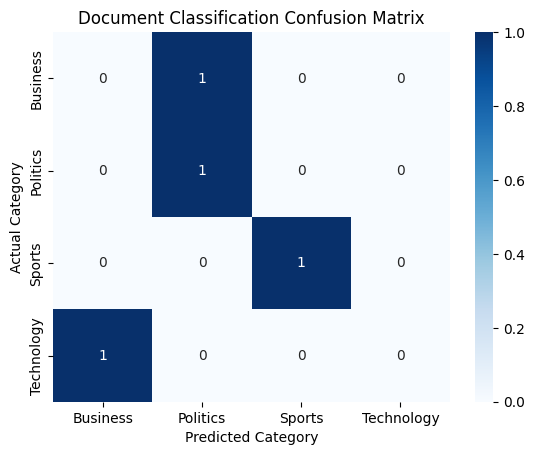

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, predictions, labels=model.classes_)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=model.classes_,
    yticklabels=model.classes_,
    cmap="Blues"
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Document Classification Confusion Matrix")
plt.show()